# Factor Exposure (Betas with Confidence Intervals)

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

A dot-and-whisker chart of the coefficients from regressing a fund's excess returns on common risk factors (market, size, value, momentum, quality), with 95% confidence intervals. It reveals what a fund is really exposed to, and whether its "alpha" survives once those exposures are accounted for.

## When to use

- Look past a fund's label to the systematic risks it takes
- Check whether outperformance is skill (alpha) or factor exposure
- Compare factor tilts across funds (small multiples or grouped dots)

## Avoid when

- Short histories (wide intervals make every coefficient look insignificant)
- Factors that are highly collinear (coefficients become unstable)

## Alternatives

- Rolling beta line chart (exposures over time)
- Table of coefficients, t-statistics and R²

## Design tips

- Draw a zero line, and note that the market beta is compared with 1, not 0
- Gray out coefficients whose interval crosses zero
- Report annualised alpha and R² in the title or a note

## Example

Five years of simulated daily returns for a fund and five long-short factors, regressed with OLS (statsmodels). The simulated fund has a market beta of 1.05, a value tilt and a small momentum tilt. Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import statsmodels.api as sm

### Data

In [2]:
rng = np.random.default_rng(3)
n = 252 * 5
factors = pd.DataFrame({
    "Market": rng.standard_t(4, n) * 0.0095 / np.sqrt(2) + 0.0003,
    "Size (SMB)": rng.normal(0, 0.005, n),
    "Value (HML)": rng.normal(0, 0.005, n),
    "Momentum": rng.normal(0, 0.007, n),
    "Quality": rng.normal(0, 0.004, n),
})
true_beta = np.array([1.05, 0.05, 0.35, 0.12, -0.02])
fund = pd.Series(0.00002 + factors.values @ true_beta + rng.normal(0, 0.006, n), name="fund_excess")
fund.head()

0    0.023879
1   -0.001434
2   -0.010532
3   -0.013023
4   -0.005081
Name: fund_excess, dtype: float64

### Plot

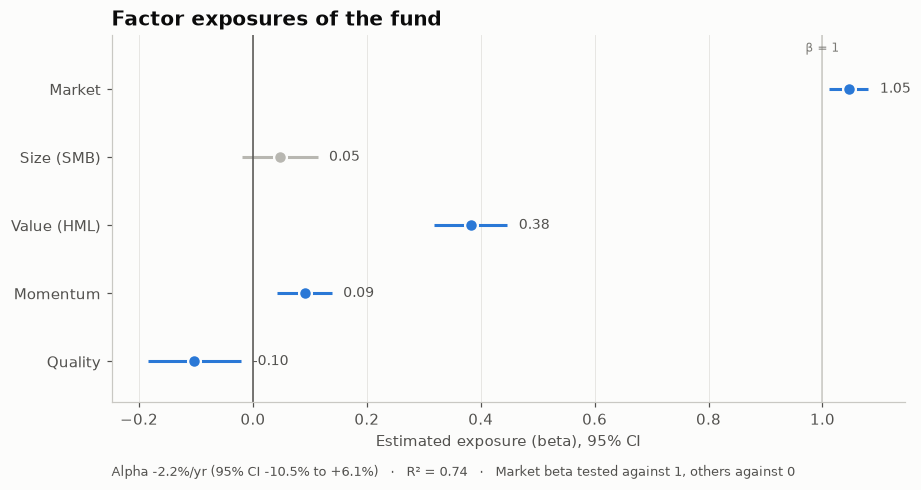

In [3]:
model = sm.OLS(fund, sm.add_constant(factors)).fit()
ci = model.conf_int(0.05)
coef = model.params.drop("const")
ci = ci.drop("const")
order = coef.index[::-1]
y = np.arange(len(order))
ref = pd.Series(0.0, index=coef.index)
ref["Market"] = 1.0
signif = (ci[0] > ref) | (ci[1] < ref)

fig, ax = plt.subplots(figsize=(8.5, 4.6))
for yi, f in zip(y, order):
    color = PALETTE[0] if signif[f] else GRAY
    ax.hlines(yi, ci.loc[f, 0], ci.loc[f, 1], color=color, linewidth=2)
    ax.scatter(coef[f], yi, s=70, color=color, zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
    ax.text(ci.loc[f, 1] + 0.02, yi, f"{coef[f]:.2f}", va="center", fontsize=9, color="#52514e")
ax.axvline(0, color="#52514e", linewidth=1)
ax.axvline(1, color="#c9c8c3", linewidth=1)
ax.text(1, len(order) - 0.45, "β = 1", ha="center", fontsize=8, color="#7a7974")
ax.set_yticks(y, order)
ax.set_xlabel("Estimated exposure (beta), 95% CI")
alpha_ann = model.params["const"] * 252
a_lo, a_hi = model.conf_int().loc["const"] * 252
ax.set_title("Factor exposures of the fund")
ax.text(0, -0.2, f"Alpha {alpha_ann:+.1%}/yr (95% CI {a_lo:+.1%} to {a_hi:+.1%})   ·   R² = {model.rsquared:.2f}"
        "   ·   Market beta tested against 1, others against 0", transform=ax.transAxes, fontsize=8.5,
        color="#52514e")
ax.grid(axis="y", visible=False)
ax.set_ylim(-0.6, len(order) - 0.2)
fig.tight_layout()
plt.show()

## How to read it

Each dot is an estimated exposure and the whisker its 95% confidence interval. Blue exposures are statistically distinguishable from zero; gray ones are not. The fund behaves like the market plus a value tilt, and its alpha interval includes zero, so there is no evidence of skill beyond these factors.

---
Standalone script: [`factor_exposure.py`](factor_exposure.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)